# Stage 06 — Feature Selection & Dimensionality Reduction

## Objective

Test whether feature reduction improves fixed-classifier development performance and report
PCA/t-SNE geometry. Keep the 74-field retrospective pool (69 numerical + five nominal),
all 22 configurations and all 110 held-fold evaluations.

## Methodology

Use the same five StratifiedGroupKFold ZIP splits, seed=42, on the 8,173 inner-training rows.
The other validation/reserved partitions do not select features. In every fitting fold,
learn numerical conditioning/kNN10, missing/One-Hot rules, completed-matrix scaling and selectors.
No full-training completed matrix or Stage 05 OOF values enter CV. Per-fold One-Hot drops
the lexical first level; Stage 05 uses a most-frequent-reference illustration. The final
StandardScaler includes indicators. Chi-square ranks uncentered indicator occurrences,
not the full presence/absence contingency table.

| Family | Fixed comparison |
|---|---|
| ANOVA | Top 10/30/50 numerical fields + all categorical indicators |
| Chi-square | Top 10/30/50 nonnegative indicators + all numerical fields |
| MI | Top 10/30/50 total columns; numerical continuous, indicators discrete; kNN=3 |
| RF / GB importance | Top 10/30/50; RF=100 trees, leaf=2; GB=50 trees, rate=.1, depth=2, leaf=5 |
| RFE | LR auxiliary estimator, step=.25; 10/30/50 total columns |
| PCA | Full SVD, whiten=False; variance targets .90/.95/.99 learned within each fold |

Every representation uses the unchanged L2 LR (C=1, lbfgs, max_iter=2000, tol=1e−4,
no class weights, seed=42, threshold=.5). Report F1-macro, balanced accuracy and continuous
class-1 ROC-AUC. Fold SD describes variability, not an independent-fold confidence interval.
Different blockwise scopes mean k is not always the same total column count.

$$
F_j=\frac{SS_{between,j}/(C-1)}{SS_{within,j}/(n-C)},\qquad
\chi_j^2=\sum_c\frac{(O_{jc}-E_{jc})^2}{E_{jc}},\qquad
I(X_j;Y)=\sum_{x,y}p(x,y)\log\frac{p(x,y)}{p(x)p(y)}.
$$

$$
Z=U\Sigma V^T,\qquad EVR_j=\lambda_j/\sum_\ell\lambda_\ell,\qquad
q_\tau=\min\{q:\sum_{j=1}^q EVR_j\geq\tau\}.
$$

ANOVA/Chi-square p-values are nominal ranking references under skewness, sparsity and ZIP
dependence. MI can capture nonlinear marginal dependence; zero-clipped estimates do not prove
independence. Tree importance has cardinality/correlation bias; RFE depends on scaled coefficients.
After freezing CV scores, fit separate unsupervised training-only PCA/t-SNE displays. The
2,000-row label-independent sample, 50 input PCs, perplexity=30, 1,000 iterations and seed=42
remain fixed. Labels only color plots; embeddings do not validate clusters or predictions.
UMAP remains an explicitly omitted optional/large-data extension.

## Implementation

This notebook reads raw data and recreates the fixed splits itself. It does not run the
encoding/scaling experiments or reuse their fitted objects. Preprocessing/ranking is cached
only within one fitting fold across k values; all five learned states are independent.
The shared helper supplies input metadata and fixed LR settings only, without fitting.

In [1]:
from pathlib import Path
import hashlib
import os
import re
import subprocess
import sys
from time import perf_counter
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML
from sklearn import config_context
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'myst.yml').is_file() and (p / 'src/validate_dataset.py').is_file()), None)
if ROOT is None or Path(sys.prefix) != ROOT / '.venv':
    raise RuntimeError('Start in the repository and use the hcmus-wids .venv kernel.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.tabular_data import (load_data, split_data, numerical_columns, numeric_audit,
    categorical_audit, prepare_numeric_training, memory_gib, CLINICAL_FIELDS,
    CATEGORICAL_FEATURES, REPRESENTATIVE_FEATURES, MISSING_TOKEN, LR_SETTINGS, KNN_MEMORY_MIB)

DATA_PATH = ROOT / 'data/raw/training.csv'
ID, TARGET, ZIP = 'patient_id', 'DiagPeriodL90D', 'patient_zip3'
df, raw_sha_before = load_data(ROOT)
train_index, validation_index, reserved_index = split_data(df)
clinical_fields = CLINICAL_FIELDS.copy()
FEATURES = REPRESENTATIVE_FEATURES.copy()
forbidden = clinical_fields | {ID, TARGET, ZIP, *CATEGORICAL_FEATURES, 'patient_gender'}
numerical_candidates = numerical_columns(df)
numerical_eligibility, bounded_share_features = numeric_audit(df, train_index, validation_index)
EXPANDED_FEATURES = numerical_candidates.copy()
air_features = {'Ozone', 'PM25', 'N02'}
frame_hash_before = hashlib.sha256(pd.util.hash_pandas_object(df, index=True).to_numpy().tobytes()).hexdigest()
dtypes_before, shape_before, columns_before = df.dtypes.copy(), df.shape, df.columns.copy()
outlier_holdout_hashes = {name:hashlib.sha256(pd.util.hash_pandas_object(df.loc[index],index=True).to_numpy().tobytes()).hexdigest()
    for name,index in {'Validation':validation_index,'Reserved':reserved_index}.items()}
stage03_adopted_training_rows = train_index.copy()  # Preserved keep-all decision before this stage's intervention.
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi':110, 'savefig.dpi':140})

ENCODING_FEATURES = CATEGORICAL_FEATURES.copy()
ENCODING_MISSING = MISSING_TOKEN
encoding_audit = categorical_audit(df, train_index)
from sklearn.preprocessing import OneHotEncoder


### Raw predictors and grouped folds

In [2]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.feature_selection import f_classif, chi2, mutual_info_classif, RFE
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import f1_score, balanced_accuracy_score, roc_auc_score
from sklearn.exceptions import ConvergenceWarning
from itertools import combinations
from collections import Counter

STAGE06_SEED = 42
STAGE06_K = [10, 30, 50]
STAGE06_PCA_THRESHOLDS = [.90, .95, .99]
STAGE06_NUMERIC = list(numerical_candidates)
STAGE06_CATEGORICAL = list(ENCODING_FEATURES)
STAGE06_INPUTS = STAGE06_NUMERIC+STAGE06_CATEGORICAL
STAGE06_LR = LR_SETTINGS.copy()
STAGE06_RF = dict(n_estimators=100, min_samples_leaf=2, max_features="sqrt",
    bootstrap=True, class_weight=None, random_state=STAGE06_SEED, n_jobs=1)
STAGE06_GB = dict(n_estimators=50, learning_rate=.1, max_depth=2,
    min_samples_leaf=5, random_state=STAGE06_SEED)
assert len(STAGE06_INPUTS)==74 and set(STAGE06_INPUTS).isdisjoint({ID,TARGET,ZIP}|clinical_fields)
stage06_X = df.loc[train_index, STAGE06_INPUTS].copy(deep=True)
# sklearn's constant imputer recognizes np.nan; this preserves every original category/NA on a copy.
stage06_X[STAGE06_CATEGORICAL] = stage06_X[STAGE06_CATEGORICAL].astype(object).where(stage06_X[STAGE06_CATEGORICAL].notna(), np.nan)
stage06_y = df.loc[train_index, TARGET].copy()
stage06_groups = df.loc[train_index, ZIP].copy()
stage06_input_hash = hashlib.sha256(pd.util.hash_pandas_object(stage06_X,index=True).to_numpy().tobytes()).hexdigest()
stage06_gate = pd.DataFrame([{"Feature": c, "Storage dtype": str(df[c].dtype),
    "Training missing N": int(df.loc[train_index,c].isna().sum()),
    "Role": numerical_eligibility.loc[c,'Semantic role'] if c in STAGE06_NUMERIC else encoding_audit.loc[c,'Semantic meaning'],
    "Use": "Retrospective numerical candidate" if c in STAGE06_NUMERIC else
           "Retrospective nominal candidate" if c in STAGE06_CATEGORICAL else "EXCLUDED",
    "Reason / time contract": numerical_eligibility.loc[c,'Reason'] if c in STAGE06_NUMERIC else encoding_audit.loc[c,'Reason'],
    "Prospective eligibility verified": False} for c in df]).set_index("Feature")
stage06_cv = StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=STAGE06_SEED)
stage06_folds = list(stage06_cv.split(stage06_X,stage06_y,groups=stage06_groups))
stage06_fold_rows = []
for fold,(fit_pos,held_pos) in enumerate(stage06_folds):
    fit_ids,held_ids = stage06_X.index[fit_pos],stage06_X.index[held_pos]
    assert set(stage06_groups.loc[fit_ids]).isdisjoint(stage06_groups.loc[held_ids])
    assert set(stage06_y.loc[fit_ids].unique())==set(stage06_y.loc[held_ids].unique())=={0,1}
    assert fit_ids.intersection(validation_index).empty and fit_ids.intersection(reserved_index).empty
    stage06_fold_rows.append({"Fold":fold,"Fit N":len(fit_ids),"Held N":len(held_ids),
        "Fit ZIPs":stage06_groups.loc[fit_ids].nunique(),"Held ZIPs":stage06_groups.loc[held_ids].nunique(),"ZIP overlap":0,
        "Fit class0":int(stage06_y.loc[fit_ids].eq(0).sum()),"Fit class1":int(stage06_y.loc[fit_ids].eq(1).sum()),
        "Held class0":int(stage06_y.loc[held_ids].eq(0).sum()),"Held class1":int(stage06_y.loc[held_ids].eq(1).sum())})
stage06_fold_audit = pd.DataFrame(stage06_fold_rows).set_index("Fold")
display(HTML('<details><summary>Stage 06 complete eligibility gate — all 83 fields</summary><div style="overflow:auto;max-height:32rem">'+stage06_gate.to_html()+'</div></details>'))
display(stage06_fold_audit)
print("Raw primary input:",stage06_X.shape,"; reserved/other validation excluded from selection.")

,Storage dtype,Training missing N,Role,Use,Reason / time contract,Prospective eligibility verified
Feature,,,,,,
patient_id,int64,0,Protected unique patient identifier,EXCLUDED,Protected ID/outcome/geographic group key,False
patient_race,str,4023,Recorded race; nominal,Retrospective nominal candidate,Common nominal comparison; prospective availability NOT VERIFIED,False
payer_type,str,1179,Payer category; nominal,Retrospective nominal candidate,Common nominal comparison; prospective availability NOT VERIFIED,False
patient_state,str,39,Coarse geographic state; nominal,Retrospective nominal candidate,Common nominal comparison; prospective availability NOT VERIFIED,False
patient_zip3,string,0,ZIP3 geographic group key,EXCLUDED,Protected ID/outcome/geographic group key,False
patient_age,int64,0,Individual age,Retrospective numerical candidate,Index/baseline alignment unverified,False
patient_gender,str,0,Recorded gender; nominal,EXCLUDED,Constant nonmissing training category; no representation information,False
bmi,float64,5642,Individual BMI,Retrospective numerical candidate,Post-metastatic; retrospective only,False
breast_cancer_diagnosis_code,str,0,ICD-9/10 code; numeric-looking tokens are nominal,EXCLUDED,Clinical/temporal gate unresolved; treatment is post-event; description belongs to text/clinical scope,False


,Fit N,Held N,Fit ZIPs,Held ZIPs,ZIP overlap,Fit class0,Fit class1,Held class0,Held class1
Fold,,,,,,,,,
0,6539,1634,357,86,0,2452,4087,612,1022
1,6532,1641,362,81,0,2447,4085,617,1024
2,6541,1632,344,99,0,2453,4088,611,1021
3,6539,1634,362,81,0,2451,4088,613,1021
4,6541,1632,347,96,0,2453,4088,611,1021


Raw primary input: (8173, 74) ; reserved/other validation excluded from selection.


### Fold-local preprocessing

In [3]:
def make_stage06_preprocessor(numeric, categorical):
    return ColumnTransformer([
        ("numeric",Pipeline([("distance_scale",StandardScaler()),
            ("knn",KNNImputer(n_neighbors=10,weights="uniform",keep_empty_features=True))]),numeric),
        ("categorical",Pipeline([("missing",SimpleImputer(strategy="constant",fill_value=ENCODING_MISSING,keep_empty_features=True)),
            ("onehot",OneHotEncoder(drop="first",handle_unknown="ignore",sparse_output=False,dtype=np.float64))]),categorical)
    ],remainder="drop",sparse_threshold=0,n_jobs=1)

def stage06_take_columns(values, columns):
    return values[:,columns]

def stage06_top_positions(scores, k):
    scores=np.asarray(scores,dtype=float)
    if np.sum(~np.isnan(scores))<k:raise ValueError("Insufficient evaluated candidates; no silent k clipping")
    safe=np.where(np.isnan(scores),-np.inf,scores)
    return np.sort(np.argsort(-safe,kind="stable")[:k])

def stage06_rank_records(method, scores, p_values, names, groups, fold):
    order=np.argsort(-np.where(np.isnan(scores),-np.inf,scores),kind="stable")
    ranks=np.empty(len(scores),dtype=int);ranks[order]=np.arange(1,len(scores)+1)
    return [{"Method":method,"Fold":fold,"Feature":name,"Original group":group,
        "Score":float(score),"Nominal p":float(p_value),"Rank":int(rank)}
        for name,group,score,p_value,rank in zip(names,groups,scores,p_values,ranks)]

### Statistical filters

In [4]:
def stage06_statistical_scores(mixed, standardized, labels, numerical_n):
    numeric=standardized[:,:numerical_n]
    indicators=mixed[:,numerical_n:]
    assert (indicators>=0).all() and np.isin(indicators,[0.,1.]).all()
    f_scores,f_p=f_classif(numeric,labels)
    chi_scores,chi_p=chi2(indicators,labels)
    discrete=np.arange(mixed.shape[1])>=numerical_n
    mi_scores=mutual_info_classif(mixed,labels,discrete_features=discrete,n_neighbors=3,
        random_state=STAGE06_SEED,n_jobs=1)
    return {"ANOVA":(f_scores,f_p),"Chi2":(chi_scores,chi_p),
            "MI":(mi_scores,np.full(len(mi_scores),np.nan))}

print("Statistical selection: ANOVA numeric-only + categorical passthrough; Chi2 indicator-only + numerical passthrough; MI all mixed columns.")

Statistical selection: ANOVA numeric-only + categorical passthrough; Chi2 indicator-only + numerical passthrough; MI all mixed columns.


### Fixed comparison configurations

In [5]:
stage06_families=["ANOVA","Chi2","MI","RF","GB","RFE"]
stage06_config_order=["No selection"]+[f"{method} k={k}" for method in stage06_families for k in STAGE06_K]+[f"PCA {threshold:.0%}" for threshold in STAGE06_PCA_THRESHOLDS]
assert len(stage06_config_order)==22
stage06_pipelines={name:{} for name in stage06_config_order}
stage06_fold_objects={}
stage06_score_rows,stage06_rfe_rows,stage06_result_rows,stage06_runtime_rows=[],[],[],[]
stage06_selected={name:{} for name in stage06_config_order}
stage06_selected_groups={name:{} for name in stage06_config_order}
stage06_fit_checks=[]
stage06_warning_rows=[]
print("Predeclared configurations:",stage06_config_order)
print("LR:",STAGE06_LR,"; RF:",STAGE06_RF,"; GB:",STAGE06_GB)

Predeclared configurations: ['No selection', 'ANOVA k=10', 'ANOVA k=30', 'ANOVA k=50', 'Chi2 k=10', 'Chi2 k=30', 'Chi2 k=50', 'MI k=10', 'MI k=30', 'MI k=50', 'RF k=10', 'RF k=30', 'RF k=50', 'GB k=10', 'GB k=30', 'GB k=50', 'RFE k=10', 'RFE k=30', 'RFE k=50', 'PCA 90%', 'PCA 95%', 'PCA 99%']
LR: {'C': 1.0, 'l1_ratio': 0.0, 'solver': 'lbfgs', 'fit_intercept': True, 'max_iter': 2000, 'tol': 0.0001, 'class_weight': None, 'random_state': 42} ; RF: {'n_estimators': 100, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'bootstrap': True, 'class_weight': None, 'random_state': 42, 'n_jobs': 1} ; GB: {'n_estimators': 50, 'learning_rate': 0.1, 'max_depth': 2, 'min_samples_leaf': 5, 'random_state': 42}


### Grouped CV execution

In [6]:
stage06_cv_start=perf_counter()
for fold,(fit_pos,held_pos) in enumerate(stage06_folds):
    print(f"Stage 06 fold {fold+1}/5: fit fresh preprocessing and all 22 candidates",flush=True)
    fit_ids,held_ids=stage06_X.index[fit_pos],stage06_X.index[held_pos]
    raw_fit,raw_held=stage06_X.loc[fit_ids],stage06_X.loc[held_ids]
    y_fit,y_held=stage06_y.loc[fit_ids],stage06_y.loc[held_ids]
    with threadpool_limits(limits=1),config_context(working_memory=KNN_MEMORY_MIB),warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        start=perf_counter()
        prep=make_stage06_preprocessor(STAGE06_NUMERIC,STAGE06_CATEGORICAL)
        mixed_fit=prep.fit_transform(raw_fit)
        mixed_held=prep.transform(raw_held)
        final_scale=StandardScaler().fit(mixed_fit)
        z_fit,z_held=final_scale.transform(mixed_fit),final_scale.transform(mixed_held)
        prep_seconds=perf_counter()-start
        assert np.isfinite(z_fit).all() and np.isfinite(z_held).all()
        numeric_branch=prep.named_transformers_['numeric']
        observed_scale=numeric_branch.named_steps['distance_scale']
        np.testing.assert_allclose(observed_scale.mean_,raw_fit[STAGE06_NUMERIC].mean(),rtol=1e-12,atol=1e-10)
        np.testing.assert_array_equal(np.broadcast_to(observed_scale.n_samples_seen_,(len(STAGE06_NUMERIC),)),raw_fit[STAGE06_NUMERIC].count())
        # Pinned sklearn fitting-array diagnostic: confirms the imputer saw this fold, never a global matrix.
        np.testing.assert_allclose(numeric_branch.named_steps['knn']._fit_X,observed_scale.transform(raw_fit[STAGE06_NUMERIC]),equal_nan=True)
        assert final_scale.n_samples_seen_==len(fit_ids)
        encoder=prep.named_transformers_['categorical'].named_steps['onehot']
        for column,levels in zip(STAGE06_CATEGORICAL,encoder.categories_):
            expected=sorted(raw_fit[column].fillna(ENCODING_MISSING).unique())
            np.testing.assert_array_equal(levels,expected)
        names=STAGE06_NUMERIC+encoder.get_feature_names_out(STAGE06_CATEGORICAL).tolist()
        groups=STAGE06_NUMERIC+[c for c,levels in zip(STAGE06_CATEGORICAL,encoder.categories_) for _ in range(len(levels)-1)]
        numeric_n=len(STAGE06_NUMERIC);p=z_fit.shape[1]
        assert len(names)==len(groups)==p and len(set(names))==p and p-numeric_n>=max(STAGE06_K)
        stage06_fit_checks.append({"Fold":fold,"Fit N":len(fit_ids),"Transformed columns":p,
            "Training matrix MiB":z_fit.nbytes/1024**2,"Shared preparation seconds":prep_seconds,
            "Means/counts/kNN/vocabulary checked":True})
        start=perf_counter();stat_scores=stage06_statistical_scores(mixed_fit,z_fit,y_fit,numeric_n)
        stat_seconds=perf_counter()-start
        stage06_runtime_rows.append({"Fold":fold,"Step":"ANOVA/Chi2/MI joint scoring","Seconds":stat_seconds})
        score_vectors={"ANOVA":stat_scores['ANOVA'][0],"Chi2":stat_scores['Chi2'][0],"MI":stat_scores['MI'][0]}
        for method,(scores,pvalues) in stat_scores.items():
            positions=np.arange(numeric_n) if method=='ANOVA' else np.arange(numeric_n,p) if method=='Chi2' else np.arange(p)
            stage06_score_rows.extend(stage06_rank_records(method,scores,pvalues,np.array(names)[positions],np.array(groups)[positions],fold))
        ranking_models={}
        for method,model in [("RF",RandomForestClassifier(**STAGE06_RF)),("GB",GradientBoostingClassifier(**STAGE06_GB))]:
            start=perf_counter();model.fit(z_fit,y_fit);elapsed=perf_counter()-start
            ranking_models[method]=model;score_vectors[method]=model.feature_importances_.copy()
            stage06_runtime_rows.append({"Fold":fold,"Step":method+" ranking fit","Seconds":elapsed})
            stage06_score_rows.extend(stage06_rank_records(method,model.feature_importances_,np.full(p,np.nan),names,groups,fold))
        start=perf_counter();pca=PCA(svd_solver="full",whiten=False).fit(z_fit);pca_seconds=perf_counter()-start
        stage06_runtime_rows.append({"Fold":fold,"Step":"PCA full fit","Seconds":pca_seconds})
        pca_fit,pca_held=pca.transform(z_fit),pca.transform(z_held)
        representations=[("No selection","Baseline",np.arange(p),None)]
        for method in stage06_families:
            for k in STAGE06_K:
                name=f"{method} k={k}"
                if method=='RFE':
                    selector=RFE(LogisticRegression(**STAGE06_LR),n_features_to_select=k,step=.25)
                    start=perf_counter();selector.fit(z_fit,y_fit);elapsed=perf_counter()-start
                    selected=np.flatnonzero(selector.support_)
                    stage06_runtime_rows.append({"Fold":fold,"Step":name+" fit","Seconds":elapsed})
                    stage06_rfe_rows.extend({"Fold":fold,"k":k,"Feature":feature,"Original group":group,
                        "Elimination rank":int(rank),"Selected":bool(support)} for feature,group,rank,support in zip(names,groups,selector.ranking_,selector.support_))
                else:
                    selector=None
                    selected=stage06_top_positions(score_vectors[method],k)
                    if method=='ANOVA':selected=np.r_[selected,np.arange(numeric_n,p)]
                    elif method=='Chi2':selected=np.r_[np.arange(numeric_n),selected+numeric_n]
                representations.append((name,method,selected,selector))
        for threshold in STAGE06_PCA_THRESHOLDS:
            count=int(np.searchsorted(np.cumsum(pca.explained_variance_ratio_),threshold)+1)
            representations.append((f"PCA {threshold:.0%}","PCA",np.arange(count),pca))
        fold_predictions={}
        for name,family,selected,selector in representations:
            if family=='PCA':
                selected_fit,selected_held=pca_fit[:,selected],pca_held[:,selected]
                feature_set={f"PC{i+1:03d}" for i in selected};original_groups=None
                representation_steps=[("pca",pca),("columns",FunctionTransformer(stage06_take_columns,kw_args={"columns":selected}))]
            else:
                selected_fit,selected_held=z_fit[:,selected],z_held[:,selected]
                feature_set=set(np.array(names)[selected]);original_groups=set(np.array(groups)[selected])
                representation_steps=[("rfe",selector)] if family=='RFE' else [("columns",FunctionTransformer(stage06_take_columns,kw_args={"columns":selected}))]
            start=perf_counter();classifier=LogisticRegression(**STAGE06_LR).fit(selected_fit,y_fit)
            predicted=classifier.predict(selected_held);probability=classifier.predict_proba(selected_held)[:,1]
            elapsed=perf_counter()-start
            fitted_pipeline=Pipeline([("mixed",prep),("scale",final_scale),*representation_steps,("classifier",classifier)])
            stage06_pipelines[name][fold]=fitted_pipeline
            stage06_selected[name][fold]=feature_set;stage06_selected_groups[name][fold]=original_groups
            fold_predictions[name]={"prediction":predicted,"probability":probability,"held_index":held_ids}
            stage06_result_rows.append({"Configuration":name,"Family":family,"Fold":fold,"Features":len(selected),
                "Original fields selected":len(original_groups) if original_groups is not None else np.nan,
                "F1 macro":f1_score(y_held,predicted,average="macro",zero_division=0),
                "Balanced accuracy":balanced_accuracy_score(y_held,predicted),"ROC AUC class1":roc_auc_score(y_held,probability),
                "LR fit/predict seconds":elapsed,
                "Class0 recall":float((predicted[y_held.to_numpy()==0]==0).mean()),
                "Class1 recall":float((predicted[y_held.to_numpy()==1]==1).mean()),
                "Predicted class1 %":float((predicted==1).mean()*100)})
        np.testing.assert_array_equal(stage06_pipelines['No selection'][fold].predict(raw_held),fold_predictions['No selection']['prediction'])
        stage06_fold_objects[fold]={"fit_index":fit_ids,"held_index":held_ids,"preprocessor":prep,"scale":final_scale,
            "names":names,"groups":groups,"score_vectors":score_vectors,"ranking_models":ranking_models,"pca":pca,"predictions":fold_predictions}
    stage06_warning_rows.extend({"Fold":fold,"Category":item.category.__name__,"Message":str(item.message)} for item in caught)
    assert not any(issubclass(item.category,ConvergenceWarning) for item in caught),"Resolve convergence before claiming completion"
    print(f"Stage 06 fold {fold+1}/5 complete; {p} input columns; held N={len(held_ids)}",flush=True)
stage06_cv_seconds=perf_counter()-stage06_cv_start
stage06_scores=pd.DataFrame(stage06_result_rows)
stage06_score_details=pd.DataFrame(stage06_score_rows)
stage06_rfe_details=pd.DataFrame(stage06_rfe_rows)
stage06_fit_audit=pd.DataFrame(stage06_fit_checks).set_index("Fold")
stage06_runtimes=pd.DataFrame(stage06_runtime_rows)
stage06_warnings=pd.DataFrame(stage06_warning_rows)
assert len(stage06_scores)==110
print("Actual whole CV wall seconds:",stage06_cv_seconds)
display(stage06_fit_audit.round(4))
if len(stage06_warnings):display(stage06_warnings.groupby(['Category','Message']).size().rename('Occurrences').to_frame())
else:print("No Stage 06 CV warnings recorded.")

Stage 06 fold 1/5: fit fresh preprocessing and all 22 candidates


Stage 06 fold 1/5 complete; 136 input columns; held N=1634


Stage 06 fold 2/5: fit fresh preprocessing and all 22 candidates


Stage 06 fold 2/5 complete; 133 input columns; held N=1641


Stage 06 fold 3/5: fit fresh preprocessing and all 22 candidates


...

Stage 06 fold 5/5: fit fresh preprocessing and all 22 candidates


Stage 06 fold 5/5 complete; 135 input columns; held N=1632


Actual whole CV wall seconds: 29.854276208905503


,Fit N,Transformed columns,Training matrix MiB,Shared preparation seconds,Means/counts/kNN/vocabulary checked
Fold,,,,,
0,6539,136,6.7849,1.9944,True
1,6532,133,6.6281,1.8461,True
2,6541,135,6.7370,1.7837,True
3,6539,136,6.7849,1.9326,True
4,6541,135,6.7370,1.8329,True


Occurrences
Category    Message                                                        
UserWarning Found unknown categories in columns [2, 4] duri...            2
            Found unknown categories in columns [2] during ...            4

## Results

The table prints all five F1 values, actual feature-count ranges, mean and sample SD.
Full selected identities, score/p/rank tables and secondary metrics remain expandable.
The performance-versus-count figure uses actual counts. PCA scree/variance and 2D PCA/t-SNE
are separate display fits, not additional held-set estimates.

### Five-fold performance

,Feature count,Fold 0,Fold 1,Fold 2,Fold 3,Fold 4,Mean,Fold SD
Configuration,,,,,,,,
No selection,133–136,0.466550,0.426838,0.485373,0.460908,0.421101,0.452154,0.027352
ANOVA k=10,74–77,0.432397,0.436448,0.429446,0.406189,0.406116,0.422119,0.014786
ANOVA k=30,94–97,0.430935,0.438371,0.433535,0.416674,0.408853,0.425674,0.012396
ANOVA k=50,114–117,0.439576,0.433125,0.454582,0.488448,0.442850,0.451716,0.021961
Chi2 k=10,79–79,0.461776,0.425191,0.428139,0.433323,0.405301,0.430746,0.020338
Chi2 k=30,99–99,0.457758,0.436458,0.454543,0.461533,0.414466,0.444952,0.019573
Chi2 k=50,119–119,0.462966,0.428314,0.463882,0.464876,0.417312,0.447470,0.022852
MI k=10,10–10,0.385862,0.383778,0.386626,0.390163,0.392463,0.387778,0.003487
MI k=30,30–30,0.433833,0.401909,0.403049,0.431450,0.419685,0.417985,0.015140


,Balanced_accuracy,ROC_AUC,Class0_recall,Class1_recall,Predicted_class1_pct,LR_seconds,Mean original-field Jaccard
Configuration,,,,,,,
No selection,0.510129,0.543240,0.097982,0.922275,91.468324,0.247246,1.000000
ANOVA k=10,0.499348,0.537196,0.053489,0.945208,94.569761,0.049188,0.469773
ANOVA k=30,0.498762,0.537247,0.060338,0.937187,93.811652,0.099069,0.569489
ANOVA k=50,0.508247,0.543758,0.097919,0.918576,91.239574,0.171088,0.683400
Chi2 k=10,0.505235,0.549902,0.062331,0.948140,94.421668,0.171097,1.000000
Chi2 k=30,0.506318,0.548486,0.086824,0.925812,92.107370,0.206516,1.000000
Chi2 k=50,0.507309,0.544099,0.091752,0.922866,91.738522,0.231917,1.000000
MI k=10,0.500232,0.537555,0.003596,0.996868,99.669462,0.017846,0.132095
MI k=30,0.506411,0.539229,0.039840,0.972983,96.817544,0.054218,0.276880


,Method,mean,std
Original group,,,
patient_age,RF,0.246197,0.001772
bmi,RF,0.183103,0.004276
patient_race,RF,0.088822,0.004360
payer_type,RF,0.070191,0.002393
patient_state,RF,0.011950,0.001224
race_pacific,RF,0.007300,0.001224
race_black,RF,0.007025,0.000412
PM25,RF,0.006915,0.000933
widowed,RF,0.006846,0.000802


,Method,mean,std
Original group,,,
patient_age,GB,0.474391,0.027885
patient_state,GB,0.081800,0.020752
payer_type,GB,0.050165,0.015953
race_pacific,GB,0.029551,0.014442
income_household_75_to_100,GB,0.024553,0.016691
bmi,GB,0.021216,0.012264
patient_race,GB,0.020473,0.009129
race_native,GB,0.016818,0.010784
education_less_highschool,GB,0.015205,0.013161


,k,10,30,50,10,30,50,10,30,50,10,30,50,10,30,50
,Fold,0,0,0,1,1,1,2,2,2,3,3,3,4,4,4
Feature,Original group,,,,,,,,,,,,,,,
Division_East South Central,Division,2,1,1,4,4,3,4,4,3,4,4,3,3,3,2
Division_Middle Atlantic,Division,4,4,3,4,4,3,4,4,3,5,5,4,4,4,3
Division_Mountain,Division,3,3,2,3,3,1,3,3,2,3,3,2,3,3,2
Division_New England,Division,5,5,4,unavailable,unavailable,unavailable,5,5,4,5,5,4,5,5,4
Division_Pacific,Division,2,1,1,2,1,1,4,4,3,2,2,1,2,2,1
Division_South Atlantic,Division,5,5,4,4,4,3,2,1,1,3,3,2,3,3,2
Division_West North Central,Division,5,5,4,4,4,3,5,5,4,4,4,3,5,5,4
Division_West South Central,Division,3,3,1,3,3,1,4,4,3,4,4,3,3,3,2


Configuration,Fold,Selected N,Selected features / components,Original fields
No selection,0,136,"Division_East South Central, Division_Middle Atlantic, Division_Mountain, Division_New England, Division_Pacific, Division_South Atlantic, Division_West North Central, Division_West South Central, Division___WIDS_MISSING__, N02, Ozone, PM25, Region_Northeast, Region_South, Region_West, Region___WIDS_MISSING__, age_10_to_19, age_20s, age_30s, age_40s, age_50s, age_60s, age_70s, age_median, age_over_80, age_under_10, bmi, commute_time, density, disabled, divorced, education_bachelors, education_college_or_above, education_graduate, education_highschool, education_less_highschool, education_some_college, education_stem_degree, family_dual_income, family_size, farmer, female, health_uninsured, hispanic, home_ownership, home_value, housing_units, income_household_100_to_150, income_household_10_to_15, income_household_150_over, income_household_15_to_20, income_household_20_to_25, income_household_25_to_35, income_household_35_to_50, income_household_50_to_75, income_household_5_to_10, income_household_75_to_100, income_household_median, income_household_six_figure, income_household_under_5, income_individual_median, labor_force_participation, limited_english, male, married, never_married, patient_age, patient_race_Black, patient_race_Hispanic, patient_race_Other, patient_race_White, patient_race___WIDS_MISSING__, patient_state_AL, patient_state_AR, patient_state_AZ, patient_state_CA, patient_state_CO, patient_state_CT, patient_state_DE, patient_state_FL, patient_state_GA, patient_state_HI, patient_state_IA, patient_state_ID, patient_state_IL, patient_state_IN, patient_state_KS, patient_state_KY, patient_state_LA, patient_state_MD, patient_state_MI, patient_state_MN, patient_state_MO, patient_state_MS, patient_state_MT, patient_state_NC, patient_state_ND, patient_state_NE, patient_state_NH, patient_state_NJ, patient_state_NM, patient_state_NV, patient_state_NY, patient_state_OH, patient_state_OK, patient_state_OR, patient_state_PA, patient_state_SC, patient_state_SD, patient_state_TN, patient_state_TX, patient_state_UT, patient_state_VA, patient_state_WA, patient_state_WI, patient_state_WV, patient_state_WY, patient_state___WIDS_MISSING__, payer_type_MEDICAID, payer_type_MEDICARE ADVANTAGE, payer_type___WIDS_MISSING__, population, poverty, race_asian, race_black, race_multiple, race_native, race_other, race_pacific, race_white, rent_burden, rent_median, self_employed, unemployment_rate, veteran, widowed","Division, N02, Ozone, PM25, Region, age_10_to_19, age_20s, age_30s, age_40s, age_50s, age_60s, age_70s, age_median, age_over_80, age_under_10, bmi, commute_time, density, disabled, divorced, education_bachelors, education_college_or_above, education_graduate, education_highschool, education_less_highschool, education_some_college, education_stem_degree, family_dual_income, family_size, farmer, female, health_uninsured, hispanic, home_ownership, home_value, housing_units, income_household_100_to_150, income_household_10_to_15, income_household_150_over, income_household_15_to_20, income_household_20_to_25, income_household_25_to_35, income_household_35_to_50, income_household_50_to_75, income_household_5_to_10, income_household_75_to_100, income_household_median, income_household_six_figure, income_household_under_5, income_individual_median, labor_force_participation, limited_english, male, married, never_married, patient_age, patient_race, patient_state, payer_type, population, poverty, race_asian, race_black, race_multiple, race_native, race_other, race_pacific, race_white, rent_burden, rent_median, self_employed, unemployment_rate, veteran, widowed"
No selection,1,133,"Division_East South Central, Division_Middle Atlantic, Division_Mountain, Division_Pacific, Division_South Atlantic, Division_West North Central, Division_West South Central, Division___WIDS_MISSING__, N02, Ozone, PM25, Region_Northeast, Region_South, Region_West, Reg

Fold,Step,Seconds
0,ANOVA/Chi2/MI joint scoring,0.89635
0,RF ranking fit,0.88361
0,GB ranking fit,1.02680
0,PCA full fit,0.05700
0,RFE k=10 fit,0.18499
0,RFE k=30 fit,0.17492
0,RFE k=50 fit,0.16699
1,ANOVA/Chi2/MI joint scoring,0.84486
1,RF ranking fit,0.84657
1,GB ranking fit,0.98684


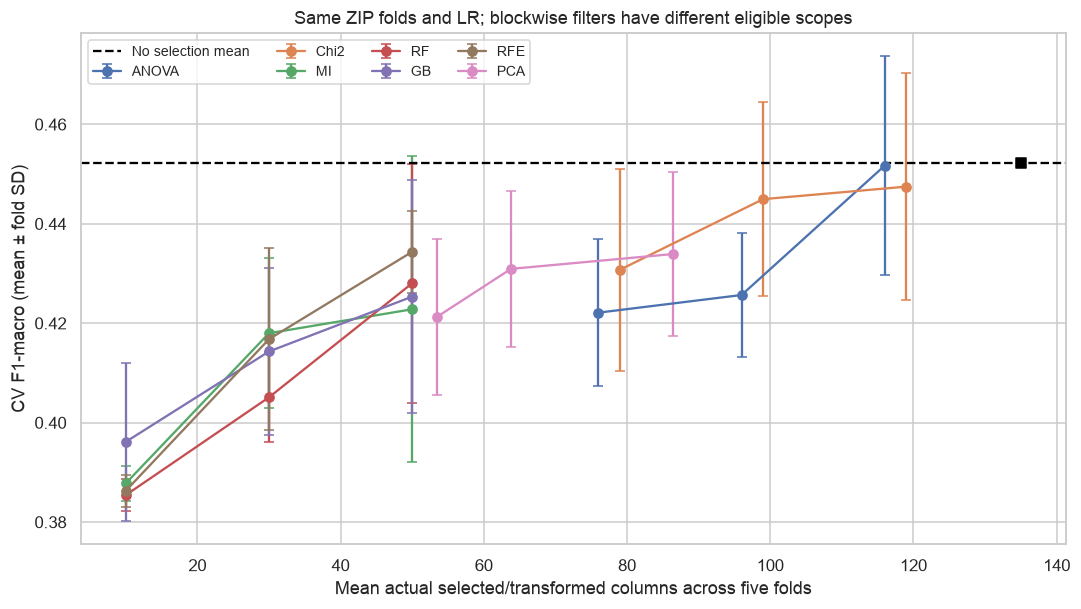

In [7]:
stage06_stability_rows=[]
for name in stage06_config_order:
    if name.startswith('PCA '):
        stage06_stability_rows.append({"Configuration":name,"Mean column Jaccard":np.nan,"Mean original-field Jaccard":np.nan})
        continue
    column_values=[];group_values=[]
    for left,right in combinations(range(5),2):
        a,b=stage06_selected[name][left],stage06_selected[name][right]
        c,d=stage06_selected_groups[name][left],stage06_selected_groups[name][right]
        column_values.append(len(a&b)/len(a|b));group_values.append(len(c&d)/len(c|d))
    stage06_stability_rows.append({"Configuration":name,"Mean column Jaccard":np.mean(column_values),"Mean original-field Jaccard":np.mean(group_values)})
stage06_stability=pd.DataFrame(stage06_stability_rows).set_index('Configuration')
stage06_f1_folds=stage06_scores.pivot(index='Configuration',columns='Fold',values='F1 macro').reindex(stage06_config_order)
stage06_f1_folds.columns=[f"Fold {i}" for i in stage06_f1_folds.columns]
stage06_cv_summary=stage06_scores.groupby('Configuration',sort=False).agg(
    Family=('Family','first'),Features_min=('Features','min'),Features_max=('Features','max'),Features_mean=('Features','mean'),
    F1_mean=('F1 macro','mean'),F1_SD=('F1 macro','std'),Balanced_accuracy=('Balanced accuracy','mean'),
    ROC_AUC=('ROC AUC class1','mean'),LR_seconds=('LR fit/predict seconds','sum'),Class0_recall=('Class0 recall','mean'),Class1_recall=('Class1 recall','mean'),Predicted_class1_pct=('Predicted class1 %','mean')).reindex(stage06_config_order)
stage06_cv_summary=stage06_cv_summary.join(stage06_f1_folds).join(stage06_stability)
stage06_selected_table=pd.DataFrame([{"Configuration":name,"Fold":fold,"Selected N":len(features),
    "Selected features / components":', '.join(sorted(features)),
    "Original fields":', '.join(sorted(stage06_selected_groups[name][fold])) if stage06_selected_groups[name][fold] is not None else 'PCA mixes inputs; no original-field subset'}
    for name in stage06_config_order for fold,features in stage06_selected[name].items()])
stage06_score_wide={method:table.pivot(index=['Feature','Original group'],columns='Fold',values=['Score','Nominal p','Rank'])
    for method,table in stage06_score_details.groupby('Method',sort=False)}
stage06_rfe_wide=stage06_rfe_details.pivot(index=['Feature','Original group'],columns=['k','Fold'],values='Elimination rank')
stage06_group_importance=stage06_score_details[stage06_score_details.Method.isin(['RF','GB'])].groupby(['Method','Fold','Original group']).Score.sum().reset_index()
stage06_group_importance_summary=stage06_group_importance.groupby(['Method','Original group']).Score.agg(['mean','std']).reset_index()
stage06_f1_display=stage06_f1_folds.copy()
stage06_f1_display.insert(0,'Feature count',stage06_cv_summary.Features_min.astype(str)+'–'+stage06_cv_summary.Features_max.astype(str))
stage06_f1_display['Mean']=stage06_cv_summary.F1_mean
stage06_f1_display['Fold SD']=stage06_cv_summary.F1_SD
display(HTML('<div style="overflow:auto">'+stage06_f1_display.to_html(float_format="{:.6f}".format)+'</div>'))
stage06_secondary=stage06_cv_summary[['Balanced_accuracy','ROC_AUC','Class0_recall','Class1_recall','Predicted_class1_pct','LR_seconds','Mean original-field Jaccard']]
display(HTML('<details><summary>All 22 secondary metric / class-recall / timing / stability rows</summary><div style="overflow:auto;max-height:32rem">'+stage06_secondary.to_html(float_format="{:.6f}".format)+'</div></details>'))
for method in ['RF','GB']:
    display(stage06_group_importance_summary[stage06_group_importance_summary.Method.eq(method)].nlargest(10,'mean').set_index('Original group').round(6))
for method,table in [*stage06_score_wide.items(),('RFE elimination ranks by k/fold',stage06_rfe_wide)]:
    display(HTML('<details><summary>Complete fold rankings: '+method+'</summary><div style="overflow:auto;max-height:32rem">'+table.to_html(float_format="{:.8g}".format,na_rep='unavailable')+'</div></details>'))
for title,table in [('All 110 fold selections — actual feature identities',stage06_selected_table),('Fold-local ranking/RFE/PCA runtimes (shared ranks are not refitted for each k)',stage06_runtimes)]:
    display(HTML('<details><summary>'+title+'</summary><div style="overflow:auto;max-height:32rem">'+table.to_html(index=False,float_format="{:.5f}".format)+'</div></details>'))
fig,ax=plt.subplots(figsize=(10,5.7))
for family in ['ANOVA','Chi2','MI','RF','GB','RFE','PCA']:
    rows=stage06_cv_summary[stage06_cv_summary.Family.eq(family)].sort_values('Features_mean')
    ax.errorbar(rows.Features_mean,rows.F1_mean,yerr=rows.F1_SD,marker='o',capsize=3,label=family)
baseline=stage06_cv_summary.loc['No selection']
ax.axhline(baseline.F1_mean,color='black',linestyle='--',label='No selection mean')
ax.scatter(baseline.Features_mean,baseline.F1_mean,color='black',marker='s',zorder=5)
ax.set(xlabel='Mean actual selected/transformed columns across five folds',ylabel='CV F1-macro (mean ± fold SD)',title='Same ZIP folds and LR; blockwise filters have different eligible scopes')
ax.legend(ncol=4,fontsize=9);plt.tight_layout();plt.show()

### PCA spectrum

,Variance threshold,Display-refit components,CV minimum components,CV maximum components
0,0.90,55,53,54
1,0.95,65,63,65
2,0.99,88,86,87


Component,Explained variance ratio,Cumulative explained variance
1,0.166287202,0.166287202
2,0.0993348254,0.265622027
3,0.0468063904,0.312428418
4,0.0399918033,0.352420221
5,0.0315296724,0.383949893
6,0.0258978555,0.409847749
7,0.0222992671,0.432147016
8,0.0221895834,0.454336599
9,0.0199757417,0.474312341
10,0.0185730402,0.492885381


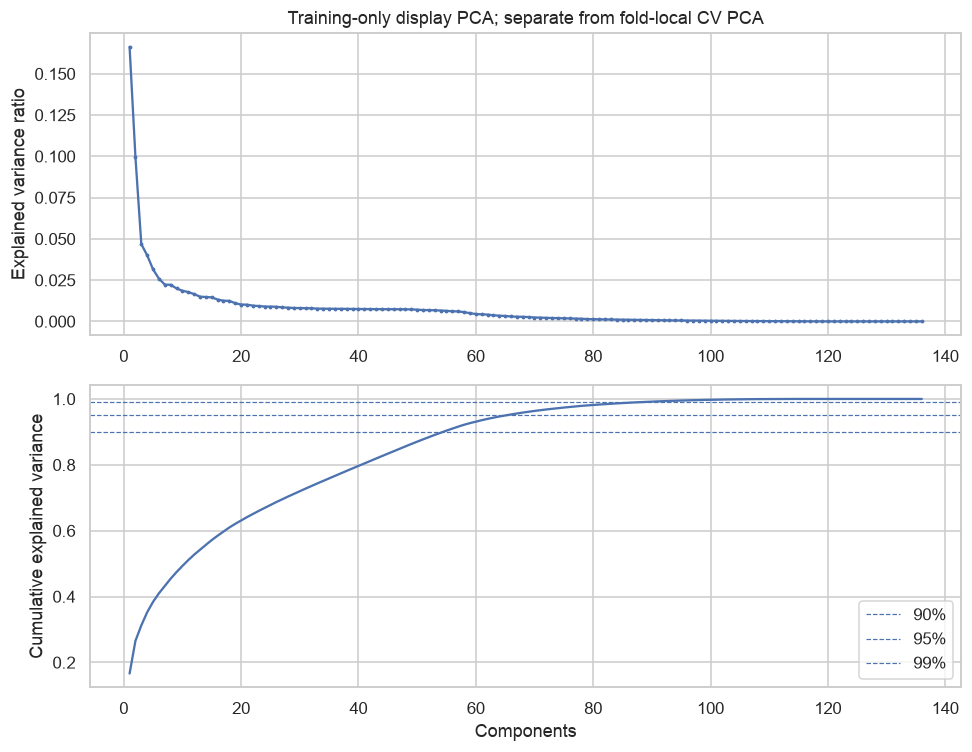

Display-only preprocessing/PCA seconds: 2.5012999998871237


In [8]:
stage06_score_hash=hashlib.sha256(pd.util.hash_pandas_object(stage06_scores,index=True).to_numpy().tobytes()).hexdigest()
with threadpool_limits(limits=1),config_context(working_memory=KNN_MEMORY_MIB):
    start=perf_counter()
    stage06_display_preprocessor=make_stage06_preprocessor(STAGE06_NUMERIC,STAGE06_CATEGORICAL)
    stage06_display_mixed=stage06_display_preprocessor.fit_transform(stage06_X)
    stage06_display_scale=StandardScaler().fit(stage06_display_mixed)
    stage06_display_z=stage06_display_scale.transform(stage06_display_mixed)
    stage06_display_pca=PCA(svd_solver='full',whiten=False).fit(stage06_display_z)
    stage06_display_coordinates=stage06_display_pca.transform(stage06_display_z)
    stage06_display_seconds=perf_counter()-start
stage06_pca_spectrum=pd.DataFrame({'Component':np.arange(1,len(stage06_display_pca.explained_variance_ratio_)+1),
    'Explained variance ratio':stage06_display_pca.explained_variance_ratio_,
    'Cumulative explained variance':np.cumsum(stage06_display_pca.explained_variance_ratio_)})
stage06_pca_thresholds=pd.DataFrame([{'Variance threshold':threshold,'Display-refit components':int(np.searchsorted(stage06_pca_spectrum['Cumulative explained variance'],threshold)+1),
    'CV minimum components':int(stage06_cv_summary.loc[f'PCA {threshold:.0%}','Features_min']),
    'CV maximum components':int(stage06_cv_summary.loc[f'PCA {threshold:.0%}','Features_max'])} for threshold in STAGE06_PCA_THRESHOLDS])
display(stage06_pca_thresholds)
display(HTML('<details><summary>Complete PCA display-refit spectrum</summary><div style="overflow:auto;max-height:32rem">'+stage06_pca_spectrum.to_html(index=False,float_format="{:.9g}".format)+'</div></details>'))
fig,axes=plt.subplots(2,1,figsize=(9,7))
axes[0].plot(stage06_pca_spectrum.Component,stage06_pca_spectrum['Explained variance ratio'],marker='.',markersize=3)
axes[0].set(ylabel='Explained variance ratio',title='Training-only display PCA; separate from fold-local CV PCA')
axes[1].plot(stage06_pca_spectrum.Component,stage06_pca_spectrum['Cumulative explained variance'])
for threshold in STAGE06_PCA_THRESHOLDS:axes[1].axhline(threshold,linestyle='--',linewidth=.8,label=f'{threshold:.0%}')
axes[1].set(xlabel='Components',ylabel='Cumulative explained variance');axes[1].legend();plt.tight_layout();plt.show()
print('Display-only preprocessing/PCA seconds:',stage06_display_seconds)

### PCA and t-SNE display

,Exploratory display diagnostics
Sample N,2000.000000
Sample ZIPs,358.000000
Available training ZIPs,443.000000
Sample class0,742.000000
Sample class1,1258.000000
t-SNE input PCs,50.000000
PCA variance retained for t-SNE,0.870376
t-SNE perplexity,30.000000
t-SNE iterations attribute,999.000000
t-SNE KL objective (not predictive quality),0.312162


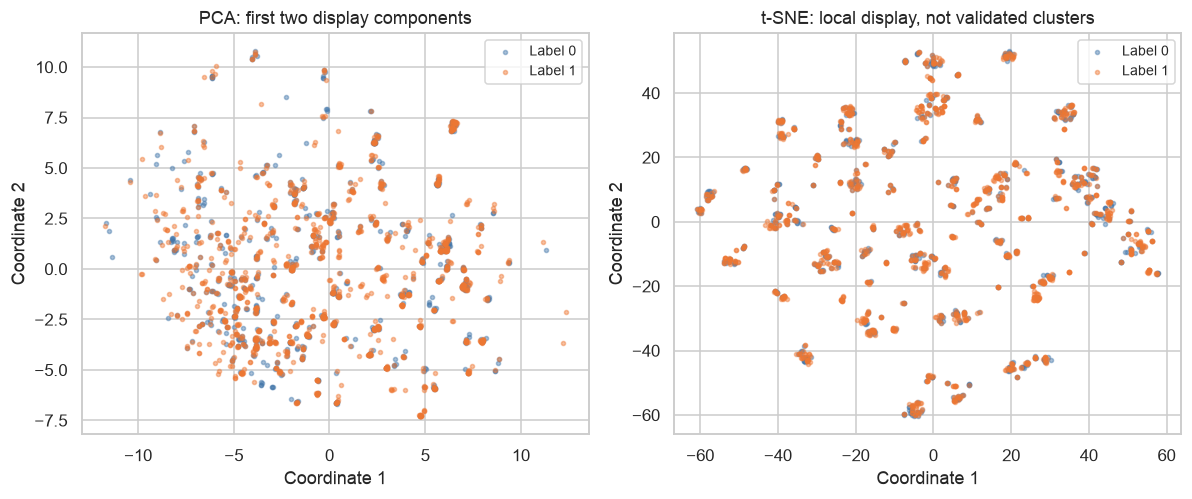

In [9]:
stage06_sample_positions=np.random.default_rng(STAGE06_SEED).choice(len(stage06_X),size=min(2000,len(stage06_X)),replace=False)
stage06_sample_index=stage06_X.index[stage06_sample_positions]
stage06_tsne_dimensions=min(50,stage06_display_coordinates.shape[1])
stage06_tsne_input=stage06_display_coordinates[stage06_sample_positions,:stage06_tsne_dimensions].copy()
stage06_tsne=TSNE(n_components=2,perplexity=30,init='pca',learning_rate='auto',max_iter=1000,
    random_state=STAGE06_SEED,method='barnes_hut',n_jobs=1)
with threadpool_limits(limits=1):
    start=perf_counter();stage06_tsne_coordinates=stage06_tsne.fit_transform(stage06_tsne_input)
    stage06_tsne_seconds=perf_counter()-start
# Outcome labels enter only plotting/reporting, never PCA/t-SNE fitting or sample selection.
stage06_plot_labels=stage06_y.loc[stage06_sample_index]
stage06_embedding_summary=pd.Series({'Sample N':len(stage06_sample_index),'Sample ZIPs':stage06_groups.loc[stage06_sample_index].nunique(),
    'Available training ZIPs':stage06_groups.nunique(),'Sample class0':int(stage06_plot_labels.eq(0).sum()),'Sample class1':int(stage06_plot_labels.eq(1).sum()),
    't-SNE input PCs':stage06_tsne_dimensions,'PCA variance retained for t-SNE':stage06_pca_spectrum.loc[stage06_tsne_dimensions-1,'Cumulative explained variance'],
    't-SNE perplexity':stage06_tsne.perplexity,'t-SNE iterations attribute':stage06_tsne.n_iter_,
    't-SNE KL objective (not predictive quality)':stage06_tsne.kl_divergence_,'t-SNE seconds':stage06_tsne_seconds})
display(stage06_embedding_summary.to_frame('Exploratory display diagnostics'))
fig,axes=plt.subplots(1,2,figsize=(11,4.7))
for ax,coordinates,title in [(axes[0],stage06_display_coordinates[stage06_sample_positions,:2],'PCA: first two display components'),
                              (axes[1],stage06_tsne_coordinates,'t-SNE: local display, not validated clusters')]:
    for label,color in [(0,'#4477AA'),(1,'#EE7733')]:
        chosen=stage06_plot_labels.to_numpy()==label
        ax.scatter(coordinates[chosen,0],coordinates[chosen,1],s=7,alpha=.45,color=color,label=f'Label {label}',rasterized=True)
    ax.set(title=title,xlabel='Coordinate 1',ylabel='Coordinate 2');ax.legend(fontsize=9)
plt.tight_layout();plt.show()

## Discussion

No reduction exceeds the no-selection mean F1=0.452154±0.027352. The best reduced candidate,
ANOVA k=50 (114–117 total columns), reaches 0.451716±0.021961: a difference of −0.000438,
not evidence of superiority or formal equivalence. Baseline class-0 recall is only 0.097982
and class-1 recall 0.922275; AUC=0.543240 exposes weak ranking and majority prediction.

Correlated alternatives and changing vocabularies affect selection stability. Original-field
importance is descriptive; aggregating dummies does not remove bias. PCA display counts
55/65/88 can differ from CV counts because its fitting population/vocabulary differs. t-SNE
layout and KL are exploratory optimization outputs, not generalization evidence.

In [10]:
stage06_best=stage06_cv_summary.F1_mean.idxmax()  # Exact ties follow predeclared order, baseline first.
stage06_best_row=stage06_cv_summary.loc[stage06_best]
stage06_baseline_row=stage06_cv_summary.loc['No selection']
stage06_delta=float(stage06_best_row.F1_mean-stage06_baseline_row.F1_mean)
stage06_best_reduced=stage06_cv_summary.loc[stage06_cv_summary.Family.ne('Baseline'),'F1_mean'].idxmax()
stage06_reduced_row=stage06_cv_summary.loc[stage06_best_reduced]
stage06_reduced_selection_frequency=pd.DataFrame([{'Original field':field,
    'Selected folds':sum(field in (stage06_selected_groups[stage06_best_reduced][fold] or set()) for fold in range(5)),
    'Role':'Categorical passthrough' if field in STAGE06_CATEGORICAL and stage06_best_reduced.startswith('ANOVA ') else 'Selected candidate'}
    for field in STAGE06_INPUTS]).set_index('Original field')
stage06_findings=pd.DataFrame([
    {'Finding':'Best observed development mean','Evidence':f'{stage06_best}: F1={stage06_best_row.F1_mean:.6f} ± {stage06_best_row.F1_SD:.6f}',
     'Implication':'Selection among the same CV comparisons; independent final estimate unavailable'},
    {'Finding':'Difference versus no selection','Evidence':f'Mean F1 difference={stage06_delta:+.6f}; baseline={stage06_baseline_row.F1_mean:.6f}',
     'Implication':'Descriptive same-fold result, not a formal independent significance test'},
    {'Finding':'Feature-count intervention','Evidence':f'Best count range={stage06_best_row.Features_min}–{stage06_best_row.Features_max}; baseline={stage06_baseline_row.Features_min}–{stage06_baseline_row.Features_max}',
     'Implication':'Blockwise ANOVA/Chi2 counts and PCA representations require their declared scope'},
    {'Finding':'Best reduced candidate','Evidence':f'{stage06_best_reduced}: F1={stage06_reduced_row.F1_mean:.6f} ± {stage06_reduced_row.F1_SD:.6f}; delta={stage06_reduced_row.F1_mean-stage06_baseline_row.F1_mean:+.6f}',
     'Implication':'Lower feature count did not exceed the no-selection mean in this fixed comparison'},
    {'Finding':'Fixed-threshold class behavior','Evidence':f'Baseline recalls: class0={stage06_baseline_row.Class0_recall:.4f}, class1={stage06_baseline_row.Class1_recall:.4f}; predicted class1={stage06_baseline_row.Predicted_class1_pct:.2f}%',
     'Implication':'Weak discrimination/majority prediction limits F1; no threshold or class-balance tuning is performed'},
    {'Finding':'Selection stability','Evidence':f"Best original-field Jaccard={stage06_best_row['Mean original-field Jaccard']:.4f}",
     'Implication':'Unavailable for PCA; compactness/overlap is not predictive correctness'},
    {'Finding':'Temporal contract','Evidence':'74 retrospective supplied-table candidates; earlier baseline not verified',
     'Implication':'No deployability or causal conclusion; eligibility must be revisited before clinical prediction'},
    {'Finding':'Next stage','Evidence':'No resampling in this stage; see Stage 07',
     'Implication':'Stage 07 evaluates resampling separately with fold-local learning'}])
display(HTML('<div style="overflow:auto">'+stage06_findings.to_html(index=False)+'</div>'))
print('Best candidate five F1 values:',stage06_f1_folds.loc[stage06_best].to_dict())
display(HTML('<details><summary>Best reduced candidate: original-field selection frequency across five folds</summary><div style="overflow:auto;max-height:32rem">'+stage06_reduced_selection_frequency.to_html()+'</div></details>'))


Finding,Evidence,Implication
Best observed development mean,No selection: F1=0.452154 ± 0.027352,Selection among the same CV comparisons; independent final estimate unavailable
Difference versus no selection,Mean F1 difference=+0.000000; baseline=0.452154,"Descriptive same-fold result, not a formal independent significance test"
Feature-count intervention,Best count range=133–136; baseline=133–136,Blockwise ANOVA/Chi2 counts and PCA representations require their declared scope
Best reduced candidate,ANOVA k=50: F1=0.451716 ± 0.021961; delta=-0.000438,Lower feature count did not exceed the no-selection mean in this fixed comparison
Fixed-threshold class behavior,"Baseline recalls: class0=0.0980, class1=0.9223; predicted class1=91.47%",Weak discrimination/majority prediction limits F1; no threshold or class-balance tuning is performed
Selection stability,Best original-field Jaccard=1.0000,Unavailable for PCA; compactness/overlap is not predictive correctness
Temporal contract,74 retrospective supplied-table candidates; earlier baseline not verified,No deployability or causal conclusion; eligibility must be revisited before clinical prediction
Next stage,No resampling in this stage; see Stage 07,Stage 07 evaluates resampling separately with fold-local learning


Best candidate five F1 values: {'Fold 0': 0.4665503826593107, 'Fold 1': 0.42683844042225544, 'Fold 2': 0.4853732293490371, 'Fold 3': 0.4609078949545763, 'Fold 4': 0.4211006384919428}


,Selected folds,Role
Original field,,
patient_age,5,Selected candidate
bmi,2,Selected candidate
population,2,Selected candidate
density,5,Selected candidate
age_median,4,Selected candidate
age_under_10,1,Selected candidate
age_10_to_19,3,Selected candidate
age_20s,2,Selected candidate
age_30s,4,Selected candidate


## Conclusion

Retain the no-selection development reference; feature reduction did not improve mean F1
in this fixed comparison. Temporal eligibility, imputation uncertainty and geographic dependence
remain. Continue with [Stage 07](07_class_imbalance.ipynb), whose numerical-only baseline is
recomputed for a controlled sampler comparison rather than compared directly with this mixed baseline.

In [11]:
stage06_checks={}
rng=np.random.default_rng(7);toy_y=np.tile([0,0,1,1],50)
toy_numeric=np.c_[toy_y+rng.normal(0,.03,200),rng.normal(size=200)]
toy_f,toy_p=f_classif(toy_numeric,toy_y)
assert toy_f[0]>toy_f[1] and toy_p[0]<toy_p[1]
toy_discrete=np.c_[np.tile([0,0,1,1],10),np.tile([0,1,0,1],10)]
toy_labels=np.tile([0,0,1,1],10)
np.testing.assert_allclose(chi2(toy_discrete,toy_labels)[0],[20,0],atol=1e-12)
np.testing.assert_allclose(mutual_info_classif(toy_discrete,toy_labels,discrete_features=True,random_state=42),[np.log(2),0],atol=1e-12)
np.testing.assert_array_equal(stage06_top_positions([.1,5,.2],2),[1,2])
np.testing.assert_array_equal(stage06_take_columns(np.arange(12).reshape(4,3),[2,0]),np.arange(12).reshape(4,3)[:,[2,0]])
with threadpool_limits(limits=1):
    toy_z=StandardScaler().fit_transform(toy_numeric)
    toy_rfe=RFE(LogisticRegression(**STAGE06_LR),n_features_to_select=1,step=1).fit(toy_z,toy_y)
assert toy_rfe.support_.tolist()==[True,False] and toy_rfe.transform(toy_z).shape==(200,1)
stage06_checks['Known F/Chi2/MI, feature-order/top-k and RFE support fixtures']=True

toy_raw=pd.DataFrame({'measure':[0.,1.,2.,np.nan,4.,5.], 'category':['a','b','a','b','a',None]})
toy_before=toy_raw.copy(deep=True)
toy_held=pd.DataFrame({'measure':[1e6,np.nan],'category':['unseen','a']})
with threadpool_limits(limits=1):
    toy_prep=make_stage06_preprocessor(['measure'],['category']).fit(toy_raw)
    train_values=toy_prep.transform(toy_raw)
    fitted_mean=toy_prep.named_transformers_['numeric'].named_steps['distance_scale'].mean_.copy()
    with warnings.catch_warnings(record=True):held_values=toy_prep.transform(toy_held)
np.testing.assert_allclose(fitted_mean,[2.4])
np.testing.assert_array_equal(toy_prep.named_transformers_['numeric'].named_steps['distance_scale'].mean_,fitted_mean)
assert np.isfinite(train_values).all() and np.isfinite(held_values).all()
np.testing.assert_allclose(held_values[0,1:],0)
pd.testing.assert_frame_equal(toy_raw,toy_before)
stage06_checks['Extreme-held/unseen-category preprocessing fixture proves train-only statistics and no input mutation']=True

toy_pca=PCA(svd_solver='full').fit(np.array([[-2,0],[-1,0],[1,0],[2,0]],dtype=float))
np.testing.assert_allclose(toy_pca.explained_variance_ratio_,[1,0])
assert int(np.searchsorted(np.cumsum(toy_pca.explained_variance_ratio_),.99)+1)==1
assert toy_pca.transform([[0.,0.]]).shape==(1,2)
stage06_checks['Known PCA spectrum/variance-threshold and transformed dimensions']=True

# Independently refit a complete raw-input sklearn Pipeline, including its selector.
repeat_fold=stage06_fold_objects[0]
with threadpool_limits(limits=1),config_context(working_memory=KNN_MEMORY_MIB),warnings.catch_warnings(record=True) as repeated_warnings:
    stage06_repeat_pipeline=clone(stage06_pipelines['RFE k=10'][0])
    stage06_repeat_pipeline.fit(stage06_X.loc[repeat_fold['fit_index']],stage06_y.loc[repeat_fold['fit_index']])
    repeated_probability=stage06_repeat_pipeline.predict_proba(stage06_X.loc[repeat_fold['held_index']])[:,1]
assert not any(issubclass(item.category,ConvergenceWarning) for item in repeated_warnings)
np.testing.assert_allclose(repeated_probability,repeat_fold['predictions']['RFE k=10']['probability'],rtol=1e-12,atol=1e-12)
np.testing.assert_array_equal(stage06_repeat_pipeline.named_steps['rfe'].support_,stage06_pipelines['RFE k=10'][0].named_steps['rfe'].support_)
stage06_checks['Independent complete Pipeline.fit from raw fold data reproduces RFE support and held probabilities']=True

assert len(stage06_folds)==5 and len(stage06_scores)==22*5
assert stage06_scores.groupby('Configuration').size().eq(5).all()
assert stage06_scores[['F1 macro','Balanced accuracy','ROC AUC class1']].apply(lambda column:column.between(0,1).all()).all()
assert stage06_fold_audit['ZIP overlap'].eq(0).all() and stage06_fit_audit['Means/counts/kNN/vocabulary checked'].all()
for fold,obj in stage06_fold_objects.items():
    assert obj['fit_index'].intersection(obj['held_index']).empty
    assert obj['fit_index'].intersection(validation_index).empty and obj['fit_index'].intersection(reserved_index).empty
    assert set(stage06_groups.loc[obj['fit_index']]).isdisjoint(stage06_groups.loc[obj['held_index']])
    for name,prediction in obj['predictions'].items():
        actual=stage06_scores[stage06_scores.Configuration.eq(name)&stage06_scores.Fold.eq(fold)].iloc[0]
        np.testing.assert_allclose(f1_score(stage06_y.loc[obj['held_index']],prediction['prediction'],average='macro',zero_division=0),actual['F1 macro'])
        classifier=stage06_pipelines[name][fold].named_steps['classifier']
        assert classifier.n_features_in_==actual.Features
        if not name.startswith('PCA '):assert stage06_selected[name][fold].issubset(obj['names'])
        else:
            threshold=float(name.split()[1].strip('%'))/100
            count=int(actual.Features);variance=np.cumsum(obj['pca'].explained_variance_ratio_)
            assert variance[count-1]>=threshold and (count==1 or variance[count-2]<threshold)
assert len({id(obj['preprocessor']) for obj in stage06_fold_objects.values()})==5
assert len({id(obj['scale']) for obj in stage06_fold_objects.values()})==5
assert all(model.n_features_in_==len(obj['names']) for obj in stage06_fold_objects.values() for model in obj['ranking_models'].values())
if len(stage06_warnings):
    assert not stage06_warnings.Category.eq('ConvergenceWarning').any()
stage06_checks['Five independent fold fits, protected holdouts, 110 metrics/pipelines and selector/PCA dimensions']=True

assert hashlib.sha256(pd.util.hash_pandas_object(stage06_scores,index=True).to_numpy().tobytes()).hexdigest()==stage06_score_hash
assert stage06_display_scale.n_samples_seen_==len(train_index)
assert stage06_sample_index.isin(train_index).all() and stage06_sample_index.is_unique
assert np.isfinite(stage06_tsne_coordinates).all() and stage06_tsne_coordinates.shape==(len(stage06_sample_index),2)
assert np.isclose(stage06_pca_spectrum['Explained variance ratio'].sum(),1)
assert stage06_tsne_input.shape[1]==stage06_tsne_dimensions
stage06_checks['CV scores frozen before separate unsupervised displays; finite PCA/t-SNE and training-only sample']=True

assert hashlib.sha256(pd.util.hash_pandas_object(stage06_X,index=True).to_numpy().tobytes()).hexdigest()==stage06_input_hash
assert hashlib.sha256(pd.util.hash_pandas_object(df,index=True).to_numpy().tobytes()).hexdigest()==frame_hash_before
for name,index in {'Validation':validation_index,'Reserved':reserved_index}.items():
    assert hashlib.sha256(pd.util.hash_pandas_object(df.loc[index],index=True).to_numpy().tobytes()).hexdigest()==outlier_holdout_hashes[name]
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()==raw_sha_before
assert set(stage06_X.columns).isdisjoint({ID,TARGET,ZIP}|clinical_fields) and stage03_adopted_training_rows.equals(train_index)
assert df.shape==(12906,83) and df.dtypes.equals(dtypes_before)
stage06_checks['Raw/schema, original rows and both external holdouts unchanged']=True
display(pd.Series(stage06_checks,name='PASS').to_frame())
print('Stage 06 complete for retrospective development comparison; no independent final estimate or deployability claim.')

,PASS
"Known F/Chi2/MI, feature-order/top-k and RFE support fixtures",True
Extreme-held/unseen-category preprocessing fixture proves train-only statistics and no input mutation,True
Known PCA spectrum/variance-threshold and transformed dimensions,True
Independent complete Pipeline.fit from raw fold data reproduces RFE support and held probabilities,True
"Five independent fold fits, protected holdouts, 110 metrics/pipelines and selector/PCA dimensions",True
CV scores frozen before separate unsupervised displays; finite PCA/t-SNE and training-only sample,True
"Raw/schema, original rows and both external holdouts unchanged",True


Stage 06 complete for retrospective development comparison; no independent final estimate or deployability claim.
